# SoundPass · Perfiles de gusto musical con K-means
**Inteligencia Artificial I · Actividad 3 · Grupo 4**
Camilo Montenegro · Esteban Parra

**Contexto.** SoundPass es la aplicación de venta de boletas para conciertos que estamos desarrollando en la materia de
Desarrollo de Aplicaciones en la Nube. Queremos que SoundPass le recomiende a cada persona **conciertos que le puedan gustar**.

**Problema.** Para recomendar hay que entender el gusto musical de la persona. Usamos el algoritmo asignado,
**K-means** (no supervisado), para descubrir **perfiles de gusto musical** a partir de cómo suenan las canciones,
y luego recomendamos los conciertos cuyos artistas suenan parecido a lo que la persona escucha.

**Datos reales.** 32.833 registros de canciones de Spotify con sus características de audio, obtenidos con la API de
Spotify (paquete `spotifyr`) y publicados por el proyecto TidyTuesday (enero de 2020). Seis géneros: pop, rap, rock,
latin, r&b y edm.

Cada paso dice **qué vamos a hacer** y **qué obtuvimos**, y cada gráfica dice **cómo leerla**.

## 0. Librerías y rutas

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import train_test_split

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src.preprocessing import (COLUMNAS_INFO, FEATURES, NOMBRES_FEATURES, cargar_canciones,
                               limpiar_canciones, perfil_por_artista, vector_desde_canciones)

FIGURAS = RAIZ / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
SEMILLA = 42
sns.set_theme(style="whitegrid")

## 1. Carga y exploración de los datos
**Qué vamos a hacer:** leer `data/raw/spotify_songs.csv`. Cada fila es una canción dentro de una playlist de Spotify,
con su artista, popularidad, género de la playlist y sus características de audio.

In [2]:
crudo = cargar_canciones(RAIZ / "data" / "raw" / "spotify_songs.csv")
print(crudo.shape)
crudo[COLUMNAS_INFO + FEATURES].head()

(32833, 23)


,track_id,track_name,track_artist,track_popularity,playlist_genre,danceability,energy,acousticness,valence
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,pop,0.748,0.916,0.1020,0.518
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,pop,0.726,0.815,0.0724,0.693
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,pop,0.675,0.931,0.0794,0.613
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,pop,0.718,0.930,0.0287,0.277
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,pop,0.650,0.833,0.0803,0.725


In [3]:
crudo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

In [4]:
print("Valores nulos por columna (solo las que tienen):")
print(crudo.isna().sum()[lambda s: s > 0])
print("Canciones repetidas (misma canción en varias playlists):", crudo["track_id"].duplicated().sum())

Valores nulos por columna (solo las que tienen):
track_name          5
track_artist        5
track_album_name    5
dtype: int64
Canciones repetidas (misma canción en varias playlists): 4477


**Qué obtuvimos:** 32.833 filas y 23 columnas. Hay 5 filas sin nombre de canción ni artista, y unas 4.500 filas repetidas
porque una misma canción aparece en varias playlists. Las limpiamos en el paso 3.

**Las características de audio** las calcula Spotify para cada canción y van de 0 a 1:

| Característica | Qué significa | Ejemplo alto | Ejemplo bajo |
|---|---|---|---|
| `danceability` (bailable) | Qué tan fácil es bailarla (ritmo estable, pulso marcado) | reguetón | balada lenta |
| `energy` (energía) | Qué tan intensa y ruidosa se siente | metal, EDM | canción de cuna |
| `acousticness` (acústico) | Qué tan probable es que sea acústica | guitarra y voz | electrónica |
| `valence` (alegría) | Qué tan positiva suena | salsa, pop alegre | canción triste |

## 2. Análisis exploratorio (EDA)
### 2.1 ¿Cuántas canciones hay de cada género?

Canciones únicas después de limpiar: 28352


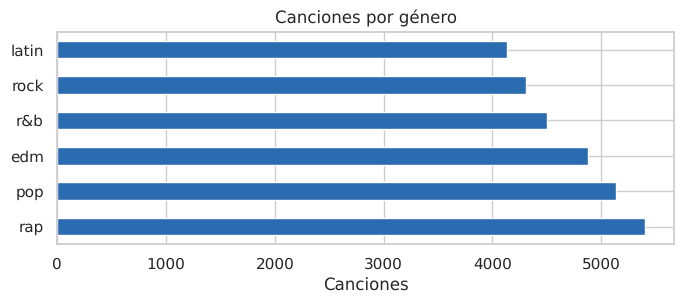

In [5]:
canciones = limpiar_canciones(crudo)
print("Canciones únicas después de limpiar:", len(canciones))
fig, ax = plt.subplots(figsize=(7, 3.2))
canciones["playlist_genre"].value_counts().plot.barh(ax=ax, color="#2b6cb0")
ax.set_xlabel("Canciones"); ax.set_ylabel(""); ax.set_title("Canciones por género")
plt.tight_layout(); plt.savefig(FIGURAS / "01_generos.png", dpi=150); plt.show()

**Cómo leer esta gráfica:** cada barra es el número de canciones de ese género.

**Qué obtuvimos:** 28.352 canciones únicas, bastante repartidas entre los 6 géneros (entre 4.100 y 5.400 cada uno).
El modelo no tendrá un género que lo domine todo.

### 2.2 Distribución de las características de audio

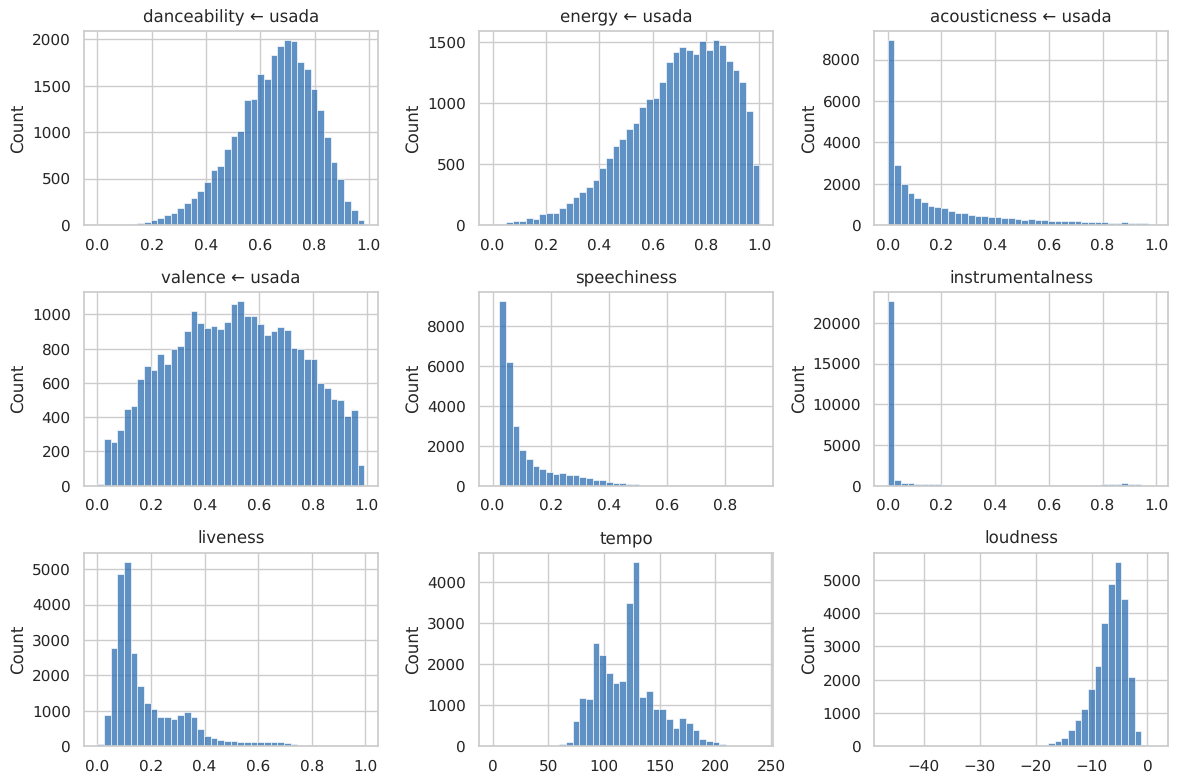

In [6]:
todas = FEATURES + ["speechiness", "instrumentalness", "liveness", "tempo", "loudness"]
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, col in zip(axes.ravel(), todas):
    sns.histplot(canciones[col], bins=40, ax=ax, color="#2b6cb0")
    ax.set_title(col + (" ← usada" if col in FEATURES else "")); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURAS / "02_distribuciones.png", dpi=150); plt.show()

**Cómo leer esta gráfica:** cada barra cuenta cuántas canciones tienen un valor en ese rango. Las marcadas con "← usada"
son las cuatro que usa el modelo.

**Qué obtuvimos:**
- `danceability`, `energy` y `valence` están repartidas a lo largo de todo el rango: diferencian bien unas canciones de otras.
- `acousticness` tiene muchas canciones cerca de 0 (la mayoría es electrónica o producida) y una cola de acústicas.
- `speechiness`, `instrumentalness` y `liveness` están casi todas pegadas a 0: casi no distinguen canciones en este
  dataset, por eso **no las usamos**. `tempo` y `loudness` están en otras escalas (BPM y decibeles) y lo que miden ya
  lo recoge en buena parte `energy`.

### 2.3 Correlaciones

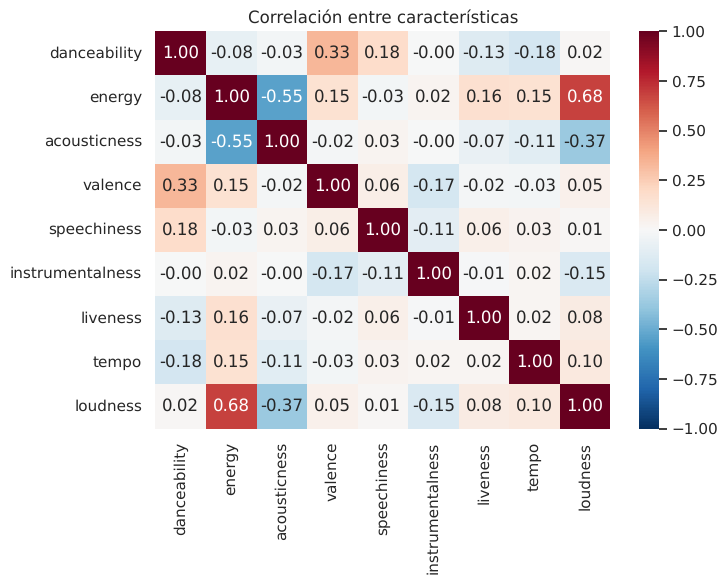

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(canciones[todas].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación entre características")
plt.tight_layout(); plt.savefig(FIGURAS / "03_correlacion.png", dpi=150); plt.show()

**Cómo leer esta gráfica:** cerca de 1 (rojo) = suben juntas; cerca de -1 (azul) = una sube cuando la otra baja.

**Qué obtuvimos:** `energy` y `acousticness` van en sentido contrario (-0,55): lo acústico suele ser tranquilo.
`energy` y `loudness` van muy juntas (0,68), por eso basta con `energy`. `danceability` y `valence` se relacionan
(0,33): lo bailable suele sonar alegre.

### 2.4 Valores atípicos

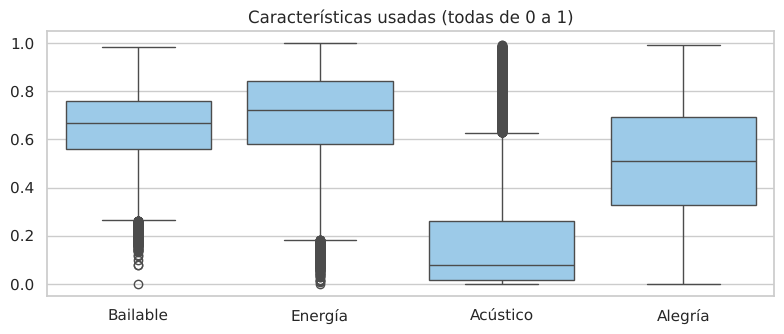

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(data=canciones[FEATURES].rename(columns=NOMBRES_FEATURES), ax=ax, color="#90cdf4")
ax.set_title("Características usadas (todas de 0 a 1)")
plt.tight_layout(); plt.savefig(FIGURAS / "04_outliers.png", dpi=150); plt.show()

**Cómo leer esta gráfica:** la caja contiene al 50 % central de las canciones; los puntos fuera de las líneas son atípicos.

**Qué obtuvimos:** hay atípicos (canciones muy acústicas, o muy poco bailables), pero son canciones reales y válidas,
así que no las quitamos. Como las cuatro características ya están en la misma escala (0 a 1), tampoco hace falta
estandarizar.

## 3. Preprocesamiento
**Qué vamos a hacer:**
1. **Limpieza:** quitar las 5 filas sin nombre y dejar una fila por canción (`limpiar_canciones`). Ya lo hicimos arriba.
2. **Selección de variables:** las 4 características que describen el "sonido": bailable, energía, acústico y alegría.
3. **Codificación / escala:** no hace falta; ya son números de 0 a 1.
4. **PCA (reducción a 2 dimensiones):** resume las 4 características en 2 ejes que conservan la mayor parte de la
   información. Lo hacemos porque K-means agrupa mejor cuando quitamos el "ruido" de las dimensiones que aportan poco
   (lo comprobamos en el paso 4.1), y además así podemos dibujar los grupos.
5. **Train/test (80/20):** PCA y K-means se ajustan solo con el 80 % y revisamos en el 20 % restante.

In [9]:
X = canciones[FEATURES].to_numpy()
idx_train, idx_test = train_test_split(np.arange(len(canciones)), test_size=0.2, random_state=SEMILLA)
X_train, X_test = X[idx_train], X[idx_test]

pca = PCA(n_components=2, random_state=SEMILLA).fit(X_train)
P_train, P_test = pca.transform(X_train), pca.transform(X_test)
print("Train:", P_train.shape, "· Test:", P_test.shape)
print("Información conservada por los 2 ejes:", f"{pca.explained_variance_ratio_.sum():.0%}")
pd.DataFrame(pca.components_, columns=[NOMBRES_FEATURES[f] for f in FEATURES], index=["Eje 1", "Eje 2"]).round(2)

Train: (22681, 2) · Test: (5671, 2)
Información conservada por los 2 ejes: 78%


,Bailable,Energía,Acústico,Alegría
Eje 1,-0.10,-0.55,0.71,-0.43
Eje 2,0.27,-0.18,0.41,0.85


**Qué obtuvimos:** los 2 ejes conservan el 78 % de la información de las 4 características. La tabla dice cómo se arma
cada eje:
- **Eje 1** sube con lo **acústico** y baja con la **energía**: va de "intenso" (izquierda) a "tranquilo/acústico" (derecha).
- **Eje 2** sube sobre todo con la **alegría** (y algo con lo acústico y lo bailable): va de "oscuro" (abajo) a "alegre" (arriba).

## 4. Entrenamiento del modelo
### 4.1 ¿Cuántos perfiles (k)? ¿Con o sin PCA?
**Qué vamos a hacer:** probar k = 2 a 8 y medir la **silueta** (de -1 a 1; el enunciado pide más de 0,4), con las
4 características directas y con los 2 ejes de PCA.

In [10]:
filas = []
for k in range(2, 9):
    km_directo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X_train)
    km_pca = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(P_train)
    filas.append({
        "k": k,
        "inercia (PCA)": km_pca.inertia_,
        "silueta sin PCA": silhouette_score(X_train, km_directo.labels_, sample_size=10000, random_state=SEMILLA),
        "silueta con PCA": silhouette_score(P_train, km_pca.labels_, sample_size=10000, random_state=SEMILLA),
    })
tabla_k = pd.DataFrame(filas).set_index("k").round(3)
tabla_k

,inercia (PCA),silueta sin PCA,silueta con PCA
k,,,
2,1777.305,0.348,0.422
3,998.071,0.308,0.424
4,807.845,0.271,0.397
5,656.030,0.266,0.349
6,530.800,0.229,0.359
7,467.430,0.228,0.361
8,410.927,0.220,0.352


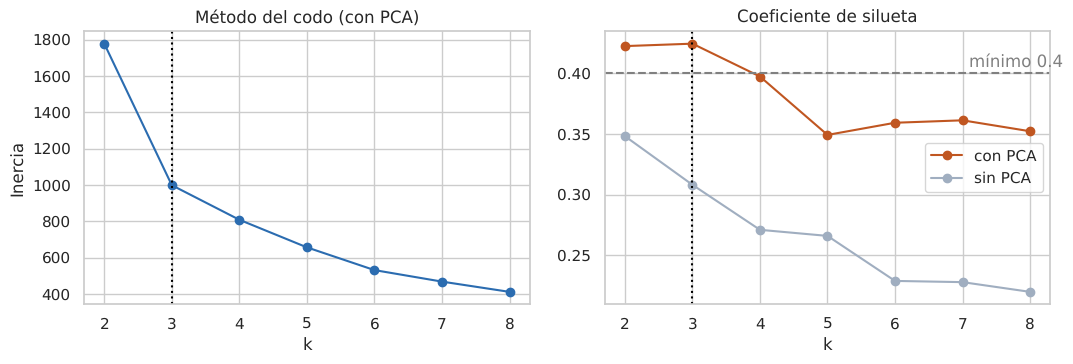

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(tabla_k.index, tabla_k["inercia (PCA)"], marker="o", color="#2b6cb0")
axes[0].set_title("Método del codo (con PCA)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inercia")
axes[1].plot(tabla_k.index, tabla_k["silueta con PCA"], marker="o", color="#c05621", label="con PCA")
axes[1].plot(tabla_k.index, tabla_k["silueta sin PCA"], marker="o", color="#a0aec0", label="sin PCA")
axes[1].axhline(0.4, ls="--", color="gray"); axes[1].text(7.1, 0.405, "mínimo 0.4", color="gray")
axes[1].set_title("Coeficiente de silueta"); axes[1].set_xlabel("k"); axes[1].legend()
for ax in axes: ax.axvline(3, ls=":", color="black")
plt.tight_layout(); plt.savefig(FIGURAS / "05_elegir_k.png", dpi=150); plt.show()

**Cómo leer esta gráfica:** a la izquierda buscamos el "codo", donde la curva deja de caer fuerte. A la derecha, más alto
es mejor; la línea gris punteada es el mínimo del enunciado.

**Qué obtuvimos:**
- **Sin PCA** la silueta se queda alrededor de 0,3: las canciones no forman grupos tan separados con las 4 variables directas.
- **Con PCA** sube por encima de 0,4 para k = 2 y k = 3.
- k = 2 solo separa "acústico" de "no acústico", que es muy poco para recomendar. **k = 3** está en el codo, supera 0,4 y da
  tres perfiles claros. Con k = 4 o más la silueta baja de 0,4.

Elegimos **k = 3 con PCA**. Para afinar dentro de cada perfil, la recomendación además ordena los conciertos por distancia
(paso 7), así que tres perfiles no limitan la recomendación a tres opciones.

### 4.2 Modelo final
**Qué vamos a hacer:** entrenar K-means con k = 3 sobre los 2 ejes de PCA del conjunto de entrenamiento.
`n_init=10` repite el algoritmo con 10 puntos de partida y se queda con el mejor.

In [12]:
K = 3
modelo = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(P_train)
print("Iteraciones hasta converger:", modelo.n_iter_)
print("Canciones por grupo (train):", np.bincount(modelo.labels_))

Iteraciones hasta converger: 9
Canciones por grupo (train): [9760 3854 9067]


## 5. Evaluación
**Qué vamos a hacer:** como no hay etiquetas, usamos métricas de clustering: **silueta** (más alto mejor),
**Davies-Bouldin** (más bajo mejor) y **Calinski-Harabasz** (más alto mejor), en train y en test.

In [13]:
etiquetas_test = modelo.predict(P_test)
metricas = pd.DataFrame({
    "train": [silhouette_score(P_train, modelo.labels_), davies_bouldin_score(P_train, modelo.labels_),
              calinski_harabasz_score(P_train, modelo.labels_)],
    "test": [silhouette_score(P_test, etiquetas_test), davies_bouldin_score(P_test, etiquetas_test),
             calinski_harabasz_score(P_test, etiquetas_test)],
}, index=["silueta", "davies_bouldin", "calinski_harabasz"]).round(3)
metricas

,train,test
silueta,0.423,0.423
davies_bouldin,0.800,0.799
calinski_harabasz,20404.910,5217.183


**Qué obtuvimos:** silueta mayor que 0,4 en train y en test, y prácticamente igual en ambos: los perfiles se sostienen
con canciones que el modelo no vio.

## 6. ¿Qué perfil es cada grupo?
**Qué vamos a hacer:** asignar todas las canciones a su grupo y mirar el promedio de cada característica, el género
y los artistas más populares de cada uno. Con eso les ponemos nombre.

In [14]:
canciones["cluster"] = modelo.predict(pca.transform(X))
resumen = canciones.groupby("cluster")[FEATURES].mean().rename(columns=NOMBRES_FEATURES).round(2)
resumen["canciones"] = canciones["cluster"].value_counts().sort_index()
resumen

,Bailable,Energía,Acústico,Alegría,canciones
cluster,,,,,
0,0.71,0.74,0.13,0.72,12221
1,0.63,0.46,0.57,0.42,4836
2,0.60,0.75,0.06,0.32,11295


**Cómo nombramos los perfiles (con reglas, no a mano):**
- El grupo **más acústico** → *Tranquilo y acústico*.
- De los otros dos, el **más alegre** → *Bailable y alegre*; el restante → *Intenso y enérgico*.

In [15]:
acustico = resumen["Acústico"].idxmax()
resto = [g for g in resumen.index if g != acustico]
alegre = max(resto, key=lambda g: resumen.loc[g, "Alegría"])
intenso = [g for g in resto if g != alegre][0]

perfiles = {
    str(alegre): {"nombre": "Bailable y alegre",
                  "descripcion": "Te gusta la música para bailar y que suena positiva: reguetón, pop latino, vallenato moderno, pop bailable."},
    str(acustico): {"nombre": "Tranquilo y acústico",
                    "descripcion": "Prefieres canciones suaves, con guitarra, piano o voz: baladas, R&B lento, indie y pop acústico."},
    str(intenso): {"nombre": "Intenso y enérgico",
                   "descripcion": "Te gusta la música con fuerza y volumen, más oscura que alegre: rock, electrónica, rap con mucha energía."},
}
canciones["perfil"] = canciones["cluster"].map(lambda g: perfiles[str(g)]["nombre"])
resumen.index = [perfiles[str(g)]["nombre"] for g in resumen.index]
resumen

,Bailable,Energía,Acústico,Alegría,canciones
Bailable y alegre,0.71,0.74,0.13,0.72,12221
Tranquilo y acústico,0.63,0.46,0.57,0.42,4836
Intenso y enérgico,0.60,0.75,0.06,0.32,11295


In [16]:
pd.crosstab(canciones["perfil"], canciones["playlist_genre"], normalize="columns").round(2)

playlist_genre,edm,latin,pop,r&b,rap,rock
perfil,,,,,,
Bailable y alegre,0.28,0.61,0.41,0.45,0.45,0.40
Intenso y enérgico,0.67,0.23,0.41,0.23,0.37,0.45
Tranquilo y acústico,0.05,0.16,0.17,0.32,0.18,0.15


**Cómo leer esta tabla:** cada columna es un género y dice qué porcentaje de sus canciones cayó en cada perfil.

**Qué obtuvimos:** el modelo nunca vio el género, pero los perfiles tienen sentido: la mayoría de canciones de **edm**
cae en *Intenso y enérgico*, las de **latin** en *Bailable y alegre*, y **r&b** es el género con más canciones en
*Tranquilo y acústico*. Los géneros no son "cajas" perfectas: una canción de pop puede ser bailable o tranquila, y por eso
recomendar por sonido es más fino que recomendar por género.

In [17]:
for nombre in ["Bailable y alegre", "Tranquilo y acústico", "Intenso y enérgico"]:
    top = (canciones[canciones["perfil"] == nombre].sort_values("track_popularity", ascending=False)
           ["track_artist"].drop_duplicates().head(8).tolist())
    print(f"{nombre}: {', '.join(top)}")

Bailable y alegre: Post Malone, KAROL G, Roddy Ricch, Dua Lipa, The Black Eyed Peas, blackbear, Regard, Bad Bunny
Tranquilo y acústico: Tones and I, Maroon 5, Billie Eilish, Justin Bieber, Lewis Capaldi, Selena Gomez, Juice WRLD, Don Toliver
Intenso y enérgico: Arizona Zervas, The Weeknd, Trevor Daniel, Camila Cabello, Travis Scott, Future, Juice WRLD, J Balvin


### 6.1 Los perfiles en el plano

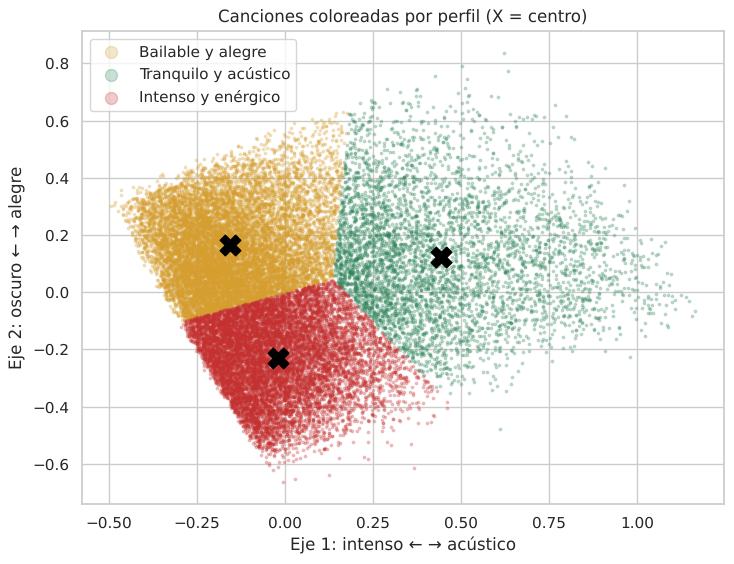

In [18]:
colores = {"Bailable y alegre": "#d69e2e", "Tranquilo y acústico": "#2f855a", "Intenso y enérgico": "#c53030"}
P_todo = pca.transform(X)
fig, ax = plt.subplots(figsize=(7.5, 5.8))
for nombre, color in colores.items():
    m = (canciones["perfil"] == nombre).to_numpy()
    ax.scatter(P_todo[m, 0], P_todo[m, 1], s=3, alpha=0.25, color=color, label=nombre)
ax.scatter(modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1], s=220, c="black", marker="X")
ax.set_xlabel("Eje 1: intenso ← → acústico"); ax.set_ylabel("Eje 2: oscuro ← → alegre")
ax.set_title("Canciones coloreadas por perfil (X = centro)")
ax.legend(markerscale=5, loc="upper left")
plt.tight_layout(); plt.savefig(FIGURAS / "06_perfiles_plano.png", dpi=150); plt.show()

**Cómo leer esta gráfica:** cada punto es una canción en los dos ejes de PCA; el color es su perfil y la X negra es el
centro del perfil. Un usuario nuevo se ubica en este mismo plano y queda en el perfil del centro más cercano.

**Qué obtuvimos:** tres zonas claras: a la derecha lo acústico, arriba a la izquierda lo bailable y alegre, y abajo lo intenso.

## 7. De perfiles a conciertos de SoundPass
**Qué vamos a hacer:** tomar el catálogo de conciertos de SoundPass (`data/raw/conciertos_soundpass.csv`, catálogo de
prueba de nuestro proyecto) y ubicar a cada artista en el mismo plano usando el **promedio de sus canciones** en el dataset.
Así cada concierto queda con un perfil y una posición, y podemos medir qué tan cerca está del gusto de una persona.

In [19]:
conciertos = pd.read_csv(RAIZ / "data" / "raw" / "conciertos_soundpass.csv")
artistas = perfil_por_artista(canciones)
faltan = set(conciertos["artista"]) - set(artistas.index)
print("Artistas de los conciertos sin canciones en el dataset:", faltan or "ninguno")

conc = conciertos.merge(artistas, left_on="artista", right_index=True, how="inner")
puntos = pca.transform(conc[FEATURES].to_numpy())
conc["pc1"], conc["pc2"] = puntos[:, 0], puntos[:, 1]
conc["cluster"] = modelo.predict(puntos)
conc["perfil"] = conc["cluster"].map(lambda g: perfiles[str(g)]["nombre"])
conc[["artista", "ciudad", "canciones", "genero_principal", "perfil"]].sort_values("perfil")

Artistas de los conciertos sin canciones en el dataset: ninguno


,artista,ciudad,canciones,genero_principal,perfil
0,KAROL G,Medellín,9,latin,Bailable y alegre
1,J Balvin,Bogotá,44,latin,Bailable y alegre
2,Maluma,Medellín,15,latin,Bailable y alegre
3,Shakira,Barranquilla,18,latin,Bailable y alegre
4,Carlos Vives,Santa Marta,16,latin,Bailable y alegre
5,Daddy Yankee,Bogotá,48,latin,Bailable y alegre
6,Ed Sheeran,Bogotá,34,pop,Bailable y alegre
7,Bruno Mars,Bogotá,20,pop,Bailable y alegre
21,The Weeknd,Bogotá,52,r&b,Intenso y enérgico
20,Soda Stereo,Medellín,22,rock,Intenso y enérgico


**Qué obtuvimos:** los 24 artistas del catálogo tienen canciones en el dataset y cada uno quedó con un perfil
(por ejemplo, Karol G y Carlos Vives en *Bailable y alegre*, Billie Eilish y Daniel Caesar en *Tranquilo y acústico*,
Metallica y Martin Garrix en *Intenso y enérgico*).

### 7.1 Prueba: recomendar a una persona
**Qué vamos a hacer:** simular a alguien que dice que le gustan tres canciones, calcular su gusto como el promedio de
esas canciones y pedir las recomendaciones con las mismas funciones que usa la app.

In [20]:
(RAIZ / "models").mkdir(exist_ok=True)
(RAIZ / "data" / "processed").mkdir(parents=True, exist_ok=True)
joblib.dump(modelo, RAIZ / "models" / "kmeans_model.pkl")
joblib.dump(pca, RAIZ / "models" / "pca.pkl")
with open(RAIZ / "models" / "perfiles.json", "w", encoding="utf-8") as f:
    json.dump(perfiles, f, ensure_ascii=False, indent=2)
with open(RAIZ / "models" / "metricas.json", "w", encoding="utf-8") as f:
    json.dump({"k": K, "varianza_pca": round(float(pca.explained_variance_ratio_.sum()), 3),
               **{f"{m}_{c}": float(metricas.loc[m, c]) for m in metricas.index for c in metricas.columns}}, f, indent=2)
conc[["id_concierto", "artista", "nombre_evento", "ciudad", "lugar", "fecha", "precio_desde_cop",
      "genero_principal", "pc1", "pc2", "cluster", "perfil"]].to_csv(
    RAIZ / "data" / "processed" / "conciertos_con_perfil.csv", index=False)
# Canciones para el buscador de la app: las más populares, una por nombre y artista.
(canciones[canciones["track_popularity"] >= 50]
 .drop_duplicates(subset=["track_name", "track_artist"])
 [COLUMNAS_INFO + FEATURES + ["perfil"]]
 .to_csv(RAIZ / "data" / "processed" / "canciones_app.csv", index=False))
for p in sorted((RAIZ / "models").iterdir()):
    print(p.name, f"{p.stat().st_size / 1024:.1f} KB")

kmeans_model.pkl 89.4 KB
metricas.json 0.2 KB
pca.pkl 1.1 KB
perfiles.json 0.5 KB


In [21]:
from src.predict import cargar_artefactos, recomendar_conciertos

art = cargar_artefactos(RAIZ)
gustos = canciones[canciones["track_name"].isin(["Tusa", "China", "Calma - Remix"])].drop_duplicates("track_name")
print("Le gustan:", ", ".join(gustos["track_name"] + " (" + gustos["track_artist"] + ")"))
perfil, recomendados = recomendar_conciertos(art, vector_desde_canciones(gustos), n=5)
print("Perfil:", perfil["nombre"])
recomendados[["artista", "nombre_evento", "ciudad", "fecha", "perfil", "afinidad"]]

Le gustan: Tusa (KAROL G), China (Anuel AA), Calma - Remix (Pedro Capó)
Perfil: Bailable y alegre


,artista,nombre_evento,ciudad,fecha,perfil,afinidad
0,J Balvin,Rayo World Tour,Bogotá,2027-04-03,Bailable y alegre,93.0
1,Shakira,Las Mujeres Ya No Lloran Tour,Barranquilla,2027-05-08,Bailable y alegre,93.0
2,Bruno Mars,24K Magic Live,Bogotá,2027-08-21,Bailable y alegre,92.0
3,Maluma,Don Juan Tour,Medellín,2027-02-20,Bailable y alegre,91.0
4,KAROL G,Tropicoqueta Tour,Medellín,2027-03-13,Bailable y alegre,90.0


**Qué obtuvimos:** a alguien que escucha reguetón el modelo lo ubica en *Bailable y alegre* y le recomienda primero
conciertos de artistas de ese mismo perfil, ordenados por qué tan parecido suenan.

## 8. Serialización
Ya guardamos con `joblib` (celda anterior):
- `models/kmeans_model.pkl`: el modelo K-means (3 centros).
- `models/pca.pkl`: el PCA, porque un usuario nuevo se tiene que transformar igual que las canciones de entrenamiento.
- `models/perfiles.json`: nombre y descripción de cada perfil.
- `data/processed/conciertos_con_perfil.csv`: cada concierto con su posición y su perfil.
- `data/processed/canciones_app.csv`: canciones populares para el buscador de la app.

## Conclusiones
- Con 28.352 canciones reales de Spotify, K-means con k = 3 sobre 2 ejes de PCA encontró tres perfiles de gusto con
  silueta mayor a 0,4 en train y en test.
- Los perfiles coinciden con lo que uno esperaría de los géneros, aunque el modelo nunca vio el género.
- SoundPass puede usar el perfil y la distancia para recomendar conciertos.
- Limitación: con 4 o más perfiles la silueta baja de 0,4; por eso la recomendación combina el perfil con la distancia.

**Referencias:** datos de Spotify Web API recopilados con `spotifyr` y publicados en TidyTuesday (rfordatascience, 2020-01-21).